# Committor Model: 1D Low-Friction Langevin Dynamics, with History

Trains a non-parametric committor (`CommittorNE`) on a long underdamped Langevin trajectory of a particle in 1D. At low friction the committor depends on position and velocity, q(λ, v), but only λ is given to the model. The velocity enters through the history: with lag d = 1 the basis is a polynomial in (λ(t−1), λ(t)), and with one frame per MD step that is equivalent to λ and the finite-difference velocity (λ(t) − λ(t−1))/dt.

**Data:** `md_istarwell2_100M/md_path.npy` (100M frames, one per step of dt = 0.005, columns λ and v; converted from `md_path.txt`). Friction γ = 1, kT = 1, m = 1.

**Potential:** `CosWellWalls`, a well of depth 1.2 kT on [−0.25, 0.25], flanked by 0.15 kT bumps and flat regions, with harmonic walls (k = 100) beyond ±0.45.

**Boundaries:** `λ <= -0.35` (A) and `λ >= 0.35` (B), the outer iSTAR interfaces

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package
import sys
sys.path.insert(0, '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/')
#sys.path.insert(0, '/home/staff7/fbsskr/Notebooks/Students/optimalrcs-cupy/')
import optimalrcs, metrics, plots

## 2. Data Loading

Loads the first `n_frames` frames (5M frames contain about 8000 A↔B transitions). The velocity `v` is only used to check the result in section 6, not in training.

In [2]:
SRC = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/md_istarwell2_100M'
n_frames = 6_000_000

data = np.load(f'{SRC}/md_path.npy', mmap_mode='r')[:n_frames*4:4]
lam, v = np.array(data[:, 0]), np.array(data[:, 1])
lambda_a, lambda_b = -0.35, 0.35
dt = 0.005                         # MD time step = time per frame
print(f'Frames: {len(lam)}')

Frames: 6000000


## 3. Free Energy Profile (FEP)

FEP along λ: the central well between the two small bumps.

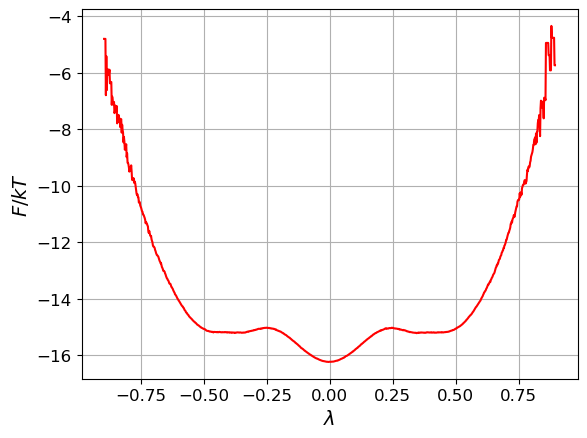

In [3]:
fig, ax = plt.subplots(1, 1)
plots.plot_fep(ax, cp.asarray(lam), xlabel='$\\lambda$')
plt.show()

## 4. Trajectory Indices

Single trajectory (`i_traj = 1` for all frames).

In [4]:
i_traj = np.ones_like(lam)          # trajectory index (1 = single trajectory)
t_traj = np.arange(len(lam))        # frame index

## 5. Train Committor (Non-Parametric), Several Seeds

`CommittorNE` rather than the equilibrium `Committor`: time reversal flips the velocity, so the reversible estimator does not apply to q(λ, v). The CVs are λ and the recorded velocity v; each iteration draws one of them.

The fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). Each fit runs in chunks of `CHUNK` iterations; after every chunk the metrics, FEPs + Z_q and observed-vs-predicted plots and the (λ, v) map are shown here and saved to `figures/langevin_seeds/seed<s>/it<N>_*.png`, and the error against the brute-force reference q(x, v) is printed.

**Warm-up (optional):** the first `WARMUP_ITER` iterations of every seed can use their own envelope (`WARMUP_ENVELOPE`), gamma (`WARMUP_GAMMA`) and CV choice (`WARMUP_CV`: `None` random, `0` λ only, `1` v only); then `ENVELOPE` and `GAMMA` take over. The seed matters through the first CVs drawn: in a test with seeds 0–3, the one run that drew v first (seed 1) reached the exact committor (RMS 0.019) and the three that drew λ first kept sharp edges at λ ≈ ±0.29 (RMS 0.052 for seed 0). `WARMUP_CV = 1` with a short warm-up tests this. `fit_transform` continues from the current RC on every call, so the chunks form one continuous run.

`lazy_basis=True` evaluates the basis in fused GPU kernels: about 4× faster here, same result. It is used instead of fewer frames: the statistical error of the comparison grows from 0.012 per bin at 6M frames to 0.020 at 2M.

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `SEEDS` | 0, 1 | Random seeds |
| `MAX_ITER` | 15000 | Iterations per seed after the warm-up |
| `CHUNK` | 5000 | Iterations between shown and saved plots |
| `ENVELOPE` | 1 | RC envelope width (`envelope_scale`) |
| `GAMMA` | 0.1 | Regularization (scales the step; does not change the fixed point) |
| `WARMUP_ITER` | 0 | Warm-up iterations (0 = off) |
| `WARMUP_ENVELOPE`, `WARMUP_GAMMA`, `WARMUP_CV` | 1, 0.1, None | Warm-up settings |
| `ny` | 6 | Polynomial degree |

#=1000, xent=0.49858, mse=0.17679, sdzq=3105.1, dzq=7930.86, dr2=2706.67, auc=0.795384, |dx|=0.163946, time=38.2874


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3408611/399208555.py:37: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)


--- figures/langevin_seeds/seed99, warmup1000 ---


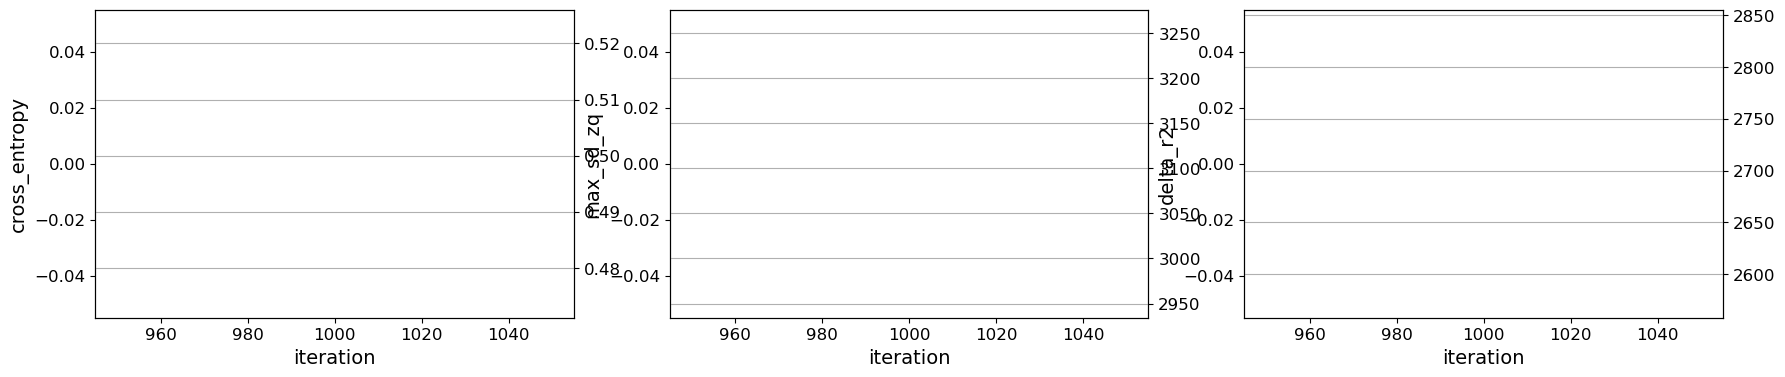

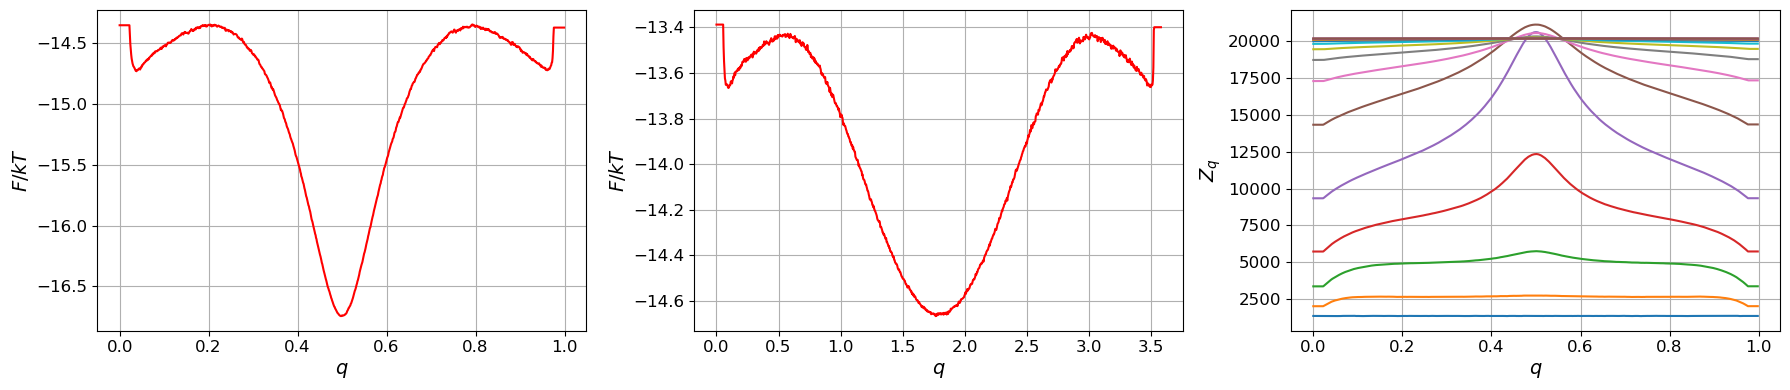

/local/data/data-fbsskr/conda_envs/RL/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


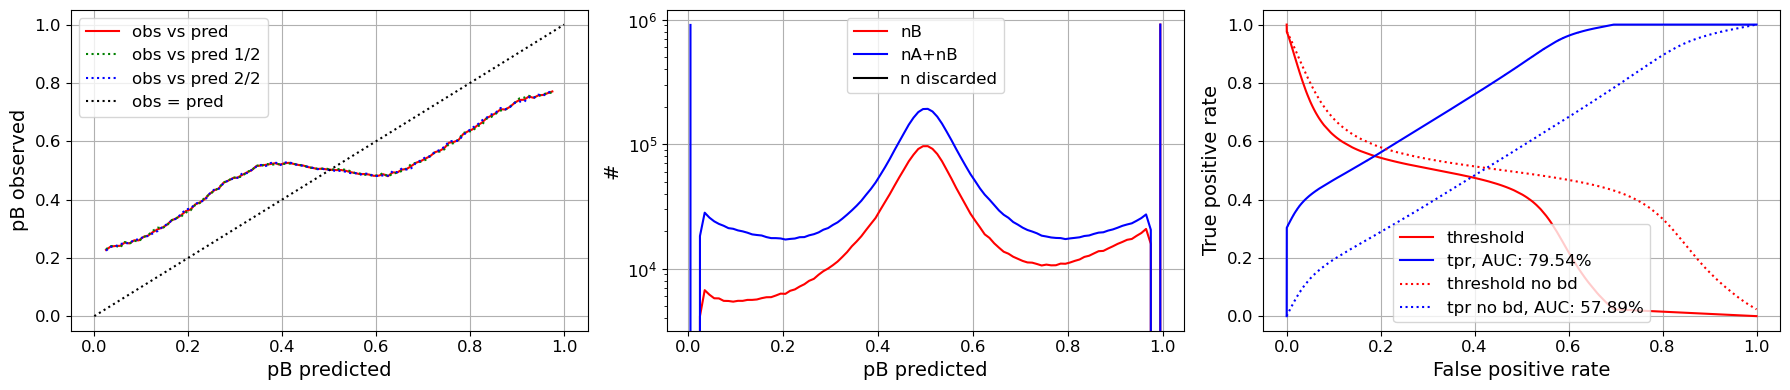

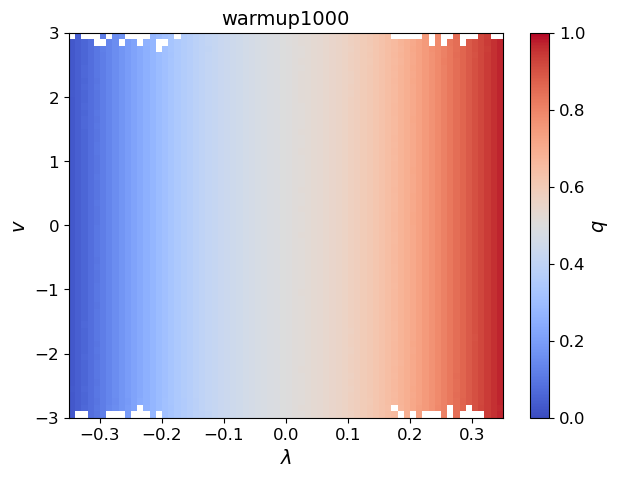

seed 99, warm-up 1000 iterations: RMS(fit - exact) per frame 0.2357

Training interrupted at iteration 1122; keeping the RC of the last completed update.



KeyboardInterrupt



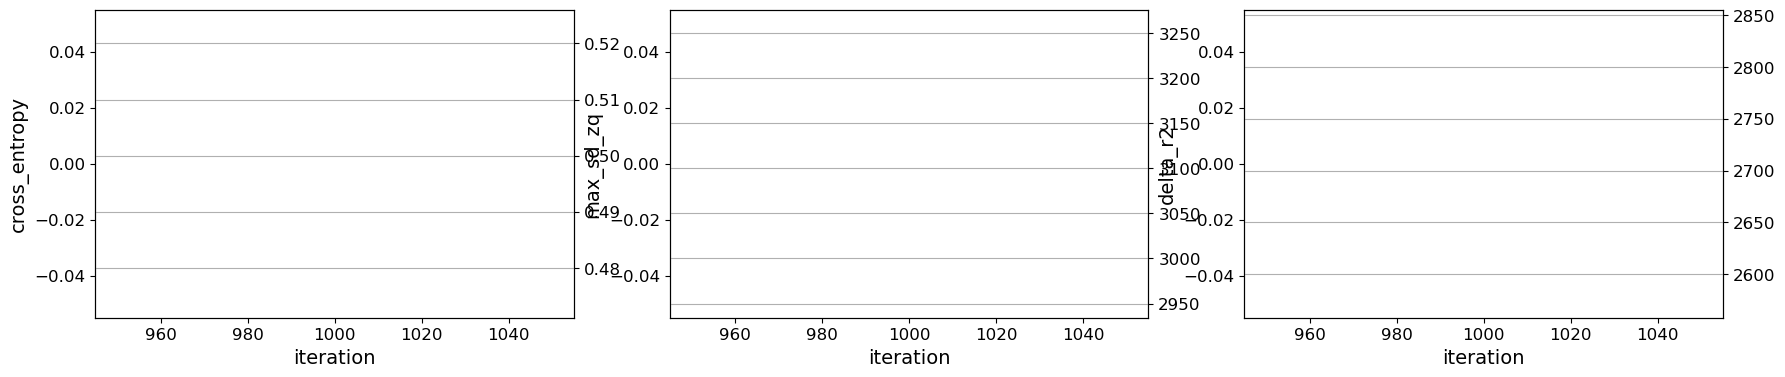

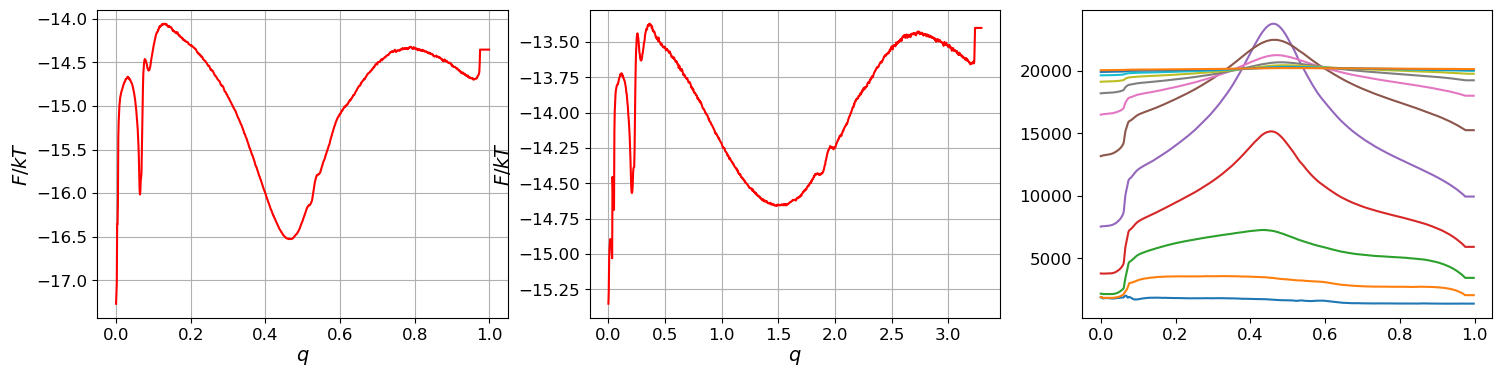

In [5]:
import os
from scipy.interpolate import RegularGridInterpolator

SEEDS = [99]
MAX_ITER = 15000
CHUNK = 5000
OUT = 'figures/langevin_seeds'

ENVELOPE = 0.01                       # envelope_scale for the main run
GAMMA = 0.1                        # regularization strength for the main run
# Optional warm-up: the first WARMUP_ITER iterations of every seed use their own envelope, gamma
# and CV choice, then the main settings take over. WARMUP_ITER = 0 switches it off.
WARMUP_ITER = 1000
WARMUP_ENVELOPE = 1
WARMUP_GAMMA = 0.1
WARMUP_CV = 0                   # None: random CV as in the main run; 0: lambda only; 1: v only
Y = cp.asarray(np.c_[lam, v])      # CVs: lambda and the recorded velocity

# brute-force reference q(x, v), for the progress printout
ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l, edges_v = np.linspace(lambda_a, lambda_b, 71), np.linspace(-3, 3, 61)
n_lv = np.histogram2d(lam, v, [edges_l, edges_v])[0]

def save_plots(q, folder, tag):
    # the library's plot methods call plt.show(); hold it off so every figure can be saved,
    # then show them all inline at the end
    show, plt.show = plt.show, (lambda *a, **k: None)
    try:
        q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
        plt.gcf().savefig(f'{folder}/{tag}_metrics.png', dpi=100)
        q.plots_feps(delta_t_sim=dt)
        plt.gcf().savefig(f'{folder}/{tag}_feps.png', dpi=100)
        q.plots_obs_pred()
        plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)
        r = cp.asnumpy(q.r_traj)
        s = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)[0]
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T,
                           cmap='coolwarm', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$\\lambda$', ylabel='$v$', title=tag)
        fig.savefig(f'{folder}/{tag}_q_lambda_v.png', dpi=100)
    finally:
        plt.show = show
    print(f'--- {folder}, {tag} ---')
    plt.show()                     # display (and close) the four figures
    return r

results = {}
for seed in SEEDS:
    folder = f'{OUT}/seed{seed}'
    os.makedirs(folder, exist_ok=True)
    np.random.seed(seed); cp.random.seed(seed)
    q = optimalrcs.CommittorNE(
        boundary0=lam <= lambda_a,     # state A
        boundary1=lam >= lambda_b,     # state B
        i_traj=i_traj,
        t_traj=t_traj,
    )
    if WARMUP_ITER > 0:
        optimalrcs.envelope_scale = WARMUP_ENVELOPE
        comp_y = (lambda: Y[:, np.random.randint(2)]) if WARMUP_CV is None else (lambda: Y[:, WARMUP_CV])
        q.fit_transform(comp_y, gamma=WARMUP_GAMMA, ny=6, max_iter=WARMUP_ITER, print_step=WARMUP_ITER,
                        save_min_delta_zq=False, lazy_basis=True)
        r = save_plots(q, folder, f'warmup{WARMUP_ITER}')
        print(f'seed {seed}, warm-up {WARMUP_ITER} iterations: RMS(fit - exact) per frame '
              f'{np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}', flush=True)
    optimalrcs.envelope_scale = ENVELOPE
    for done in range(CHUNK, MAX_ITER + 1, CHUNK):
        q.fit_transform(
            lambda: Y[:, np.random.randint(2)],
            gamma=GAMMA,
            ny=6,
            max_iter=CHUNK,
            print_step=1000,
            save_min_delta_zq=False,
            lazy_basis=True,
        )
        r = save_plots(q, folder, f'it{WARMUP_ITER + done}')
        rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        print(f'seed {seed}, {WARMUP_ITER + done} iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
    results[seed] = r

# Final RMS per seed (the plots of every chunk are shown above)
for seed, r in results.items():
    print(f'seed {seed}: RMS(fit - exact) per frame {np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}')

#=2000, xent=0.49858, mse=0.17679, sdzq=3105.1, dzq=7930.77, dr2=2706.67, auc=0.795384, |dx|=0.163946, time=57.1271


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3408744/4074971449.py:39: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)


--- figures/langevin_hist_seeds/seed99, warmup2000 ---


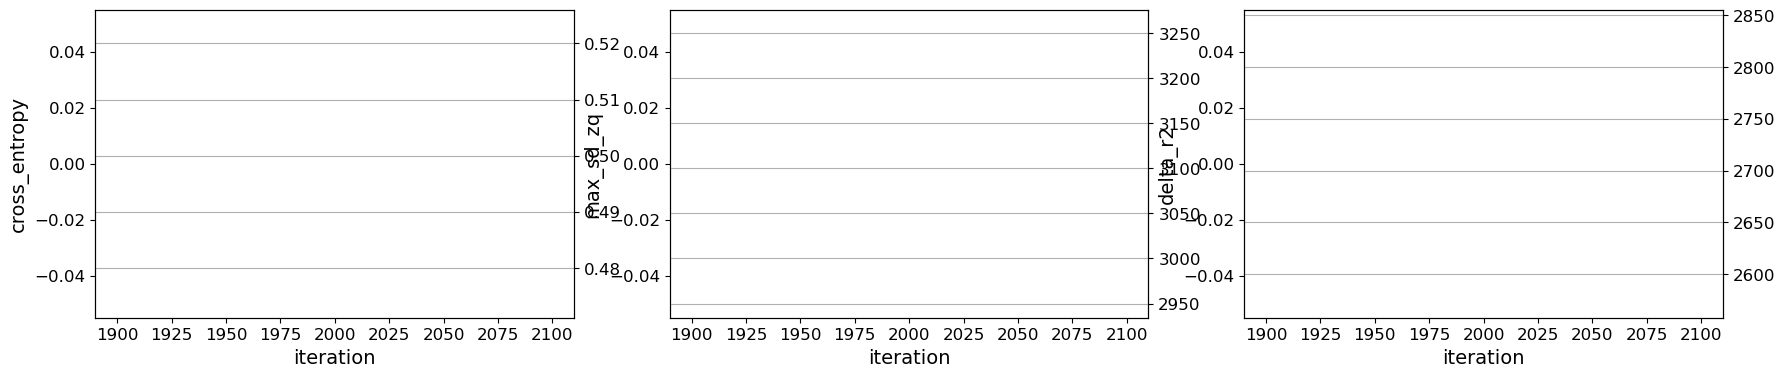

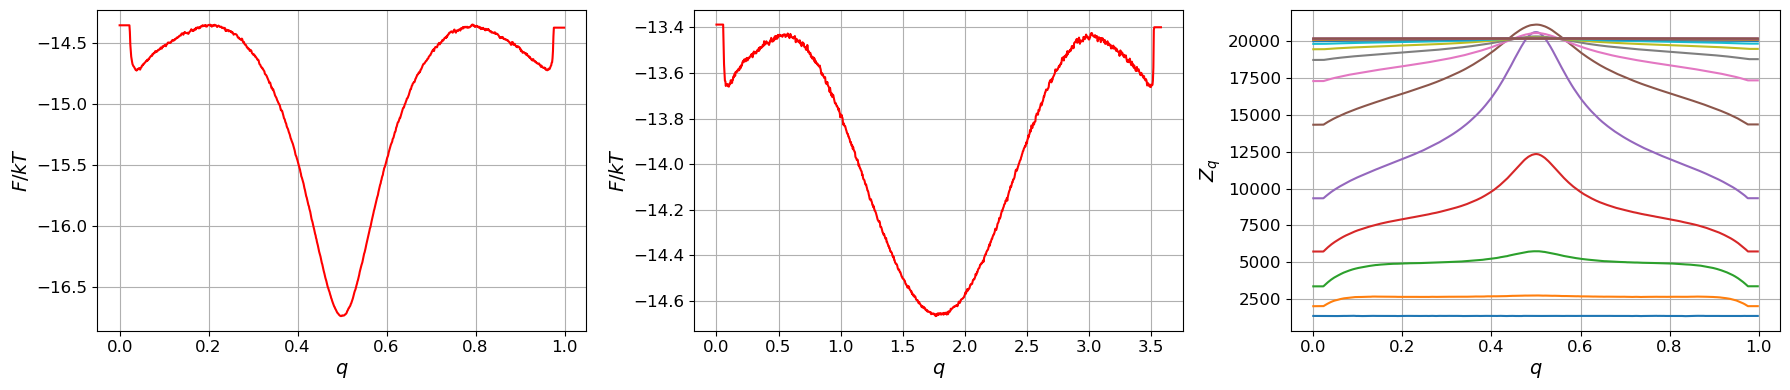

/local/data/data-fbsskr/conda_envs/RL/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


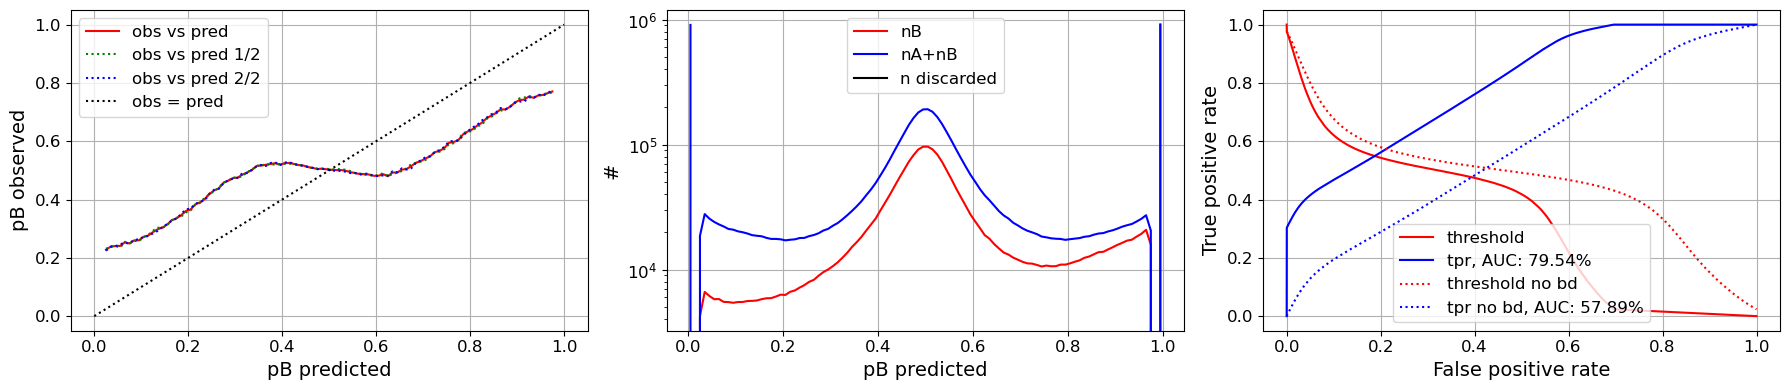

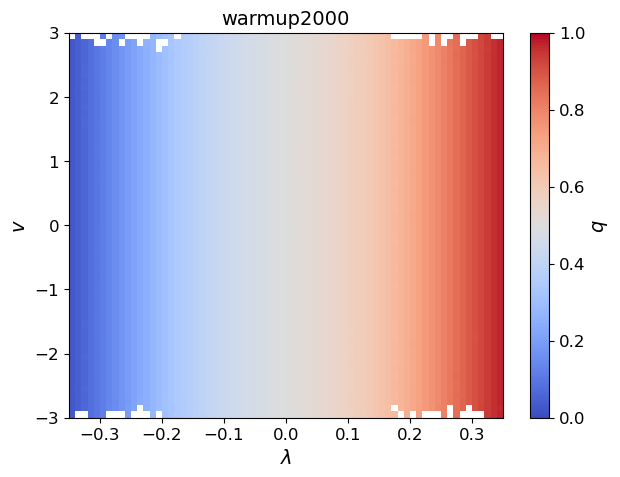

seed 99, warm-up 2000 iterations: RMS(fit - exact) per frame 0.2357
#=3000, xent=0.560772, mse=0.204093, sdzq=10102.4, dzq=28852, dr2=9326.85, auc=0.805582, |dx|=0.161174, time=24.0977
#=4000, xent=0.494252, mse=0.181599, sdzq=9532.22, dzq=26590.9, dr2=14730.2, auc=0.81251, |dx|=0.0670449, time=48.1963
#=5000, xent=0.446313, mse=0.161031, sdzq=5447.33, dzq=20370, dr2=20789.5, auc=0.824942, |dx|=0.0701808, time=72.2553
#=6000, xent=0.419697, mse=0.148696, sdzq=1655.61, dzq=7246.83, dr2=26850.8, auc=0.854539, |dx|=0.0618957, time=96.3153
#=7000, xent=0.409299, mse=0.143988, sdzq=1602.11, dzq=3579.61, dr2=32104.1, auc=0.857018, |dx|=0.0840861, time=120.376


/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3408744/4074971449.py:39: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)


--- figures/langevin_hist_seeds/seed99, it7000 ---


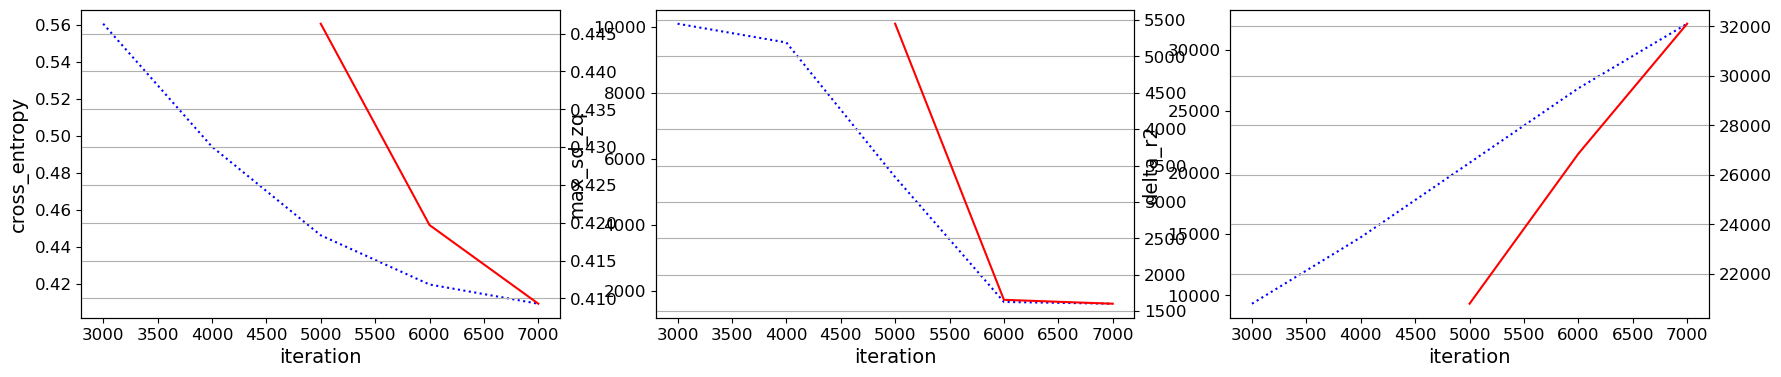

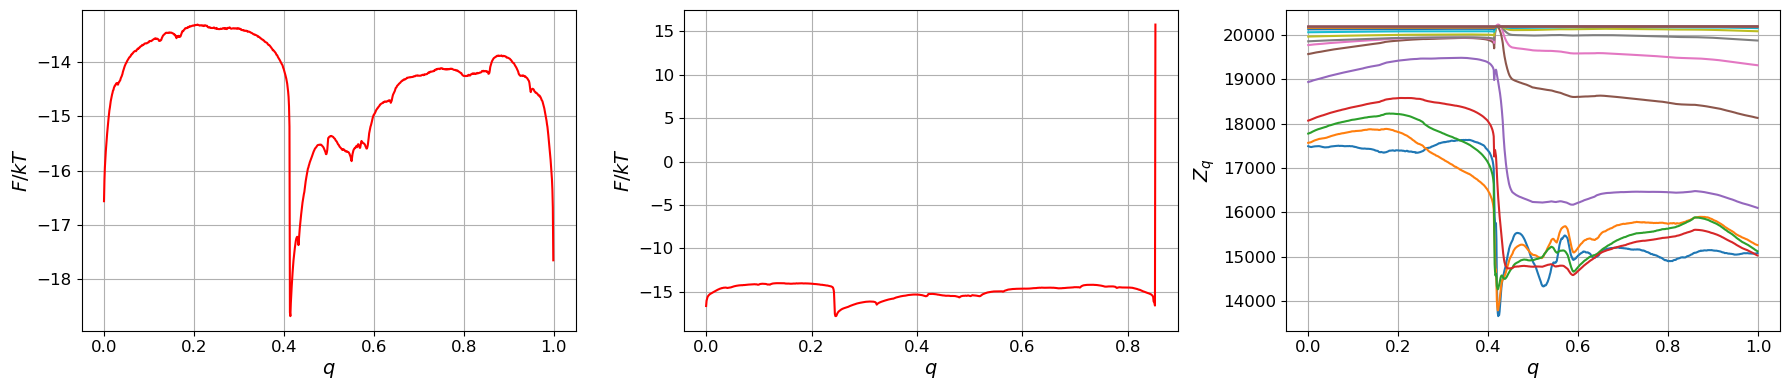

/local/data/data-fbsskr/conda_envs/RL/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


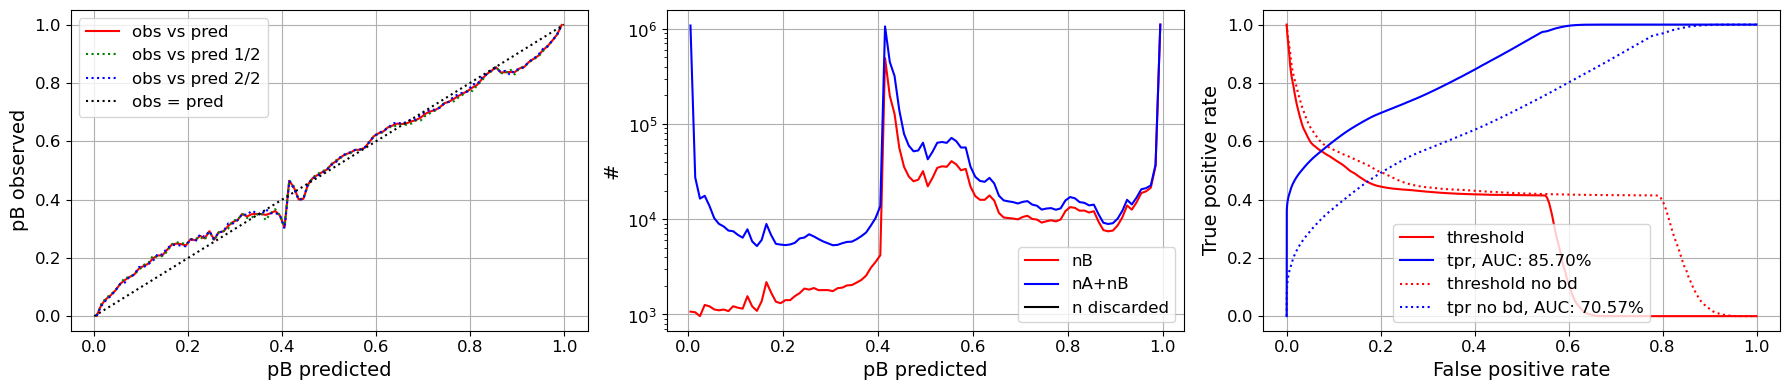

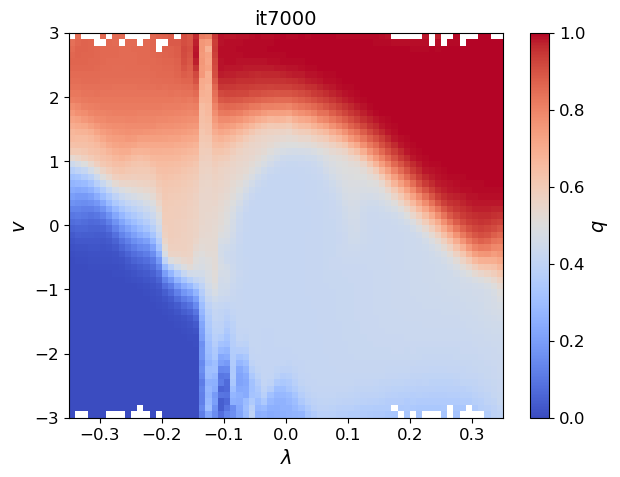

seed 99, 7000 iterations: RMS(fit - exact) per frame 0.0936, plots in figures/langevin_hist_seeds/seed99


In [ ]:
import os
from scipy.interpolate import RegularGridInterpolator

SEEDS = [99]
MAX_ITER = 15000
CHUNK = 5000
OUT = 'figures/langevin_hist_seeds'

ENVELOPE = 0.01                       # envelope_scale for the main run
GAMMA = 0.                        # regularization strength for the main run
# Optional warm-up: the first WARMUP_ITER iterations of every seed use their own envelope, gamma
# and CV choice, then the main settings take over. WARMUP_ITER = 0 switches it off.
WARMUP_ITER = 2000
WARMUP_ENVELOPE = 1000000
WARMUP_GAMMA = 0.
WARMUP_CV = 0                   # None: random CV as in the main run; 0: lambda only; 1: v only
Y = cp.asarray(np.c_[lam, v])      # CVs: lambda and the recorded velocity
history=[0,1]
yr_type=['y(t-d),y(t)']

# brute-force reference q(x, v), for the progress printout
ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l, edges_v = np.linspace(lambda_a, lambda_b, 71), np.linspace(-3, 3, 61)
n_lv = np.histogram2d(lam, v, [edges_l, edges_v])[0]

def save_plots(q, folder, tag):
    # the library's plot methods call plt.show(); hold it off so every figure can be saved,
    # then show them all inline at the end
    show, plt.show = plt.show, (lambda *a, **k: None)
    try:
        q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
        plt.gcf().savefig(f'{folder}/{tag}_metrics.png', dpi=100)
        q.plots_feps(delta_t_sim=dt)
        plt.gcf().savefig(f'{folder}/{tag}_feps.png', dpi=100)
        q.plots_obs_pred()
        plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)
        r = cp.asnumpy(q.r_traj)
        s = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)[0]
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T,
                           cmap='coolwarm', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$\\lambda$', ylabel='$v$', title=tag)
        fig.savefig(f'{folder}/{tag}_q_lambda_v.png', dpi=100)
    finally:
        plt.show = show
    print(f'--- {folder}, {tag} ---')
    plt.show()                     # display (and close) the four figures
    return r

results = {}
for seed in SEEDS:
    folder = f'{OUT}/seed{seed}'
    os.makedirs(folder, exist_ok=True)
    np.random.seed(seed); cp.random.seed(seed)
    q = optimalrcs.CommittorNE(
        boundary0=lam <= lambda_a,     # state A
        boundary1=lam >= lambda_b,     # state B
        i_traj=i_traj,
        t_traj=t_traj,
    )
    if WARMUP_ITER > 0:
        optimalrcs.envelope_scale = WARMUP_ENVELOPE
        comp_y = (lambda: Y[:, np.random.randint(2)]) if WARMUP_CV is None else (lambda: Y[:, WARMUP_CV])
        q.fit_transform(lambda: lam,
                        #comp_y,
                        gamma=WARMUP_GAMMA, 
                        #ny=6, 
                        max_iter=WARMUP_ITER, print_step=WARMUP_ITER,
                        history_delta_t=history,
                        history_type=yr_type, history_shift_type='r(t)',delta_r2_max_change_allowed=10000,
                        save_min_delta_zq=False, 
                        lazy_basis=True
                       )
        r = save_plots(q, folder, f'warmup{WARMUP_ITER}')
        print(f'seed {seed}, warm-up {WARMUP_ITER} iterations: RMS(fit - exact) per frame '
              f'{np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}', flush=True)
    optimalrcs.envelope_scale = ENVELOPE
    for done in range(CHUNK, MAX_ITER + 1, CHUNK):
        q.fit_transform(
            lambda: lam,
            #lambda: Y[:, np.random.randint(2)],
            gamma=GAMMA,
            #ny=6,
            history_delta_t=history,
            history_type=yr_type, history_shift_type='r(t)',
            max_iter=CHUNK,
            print_step=1000,
            save_min_delta_zq=False,
           lazy_basis=True,
        )
        r = save_plots(q, folder, f'it{WARMUP_ITER + done}')
        rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        print(f'seed {seed}, {WARMUP_ITER + done} iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
    results[seed] = r

# Final RMS per seed (the plots of every chunk are shown above)
for seed, r in results.items():
    print(f'seed {seed}: RMS(fit - exact) per frame {np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}')

## 6. Committor in the (λ, v) Plane

Mean q per (λ, v) bin, using the true velocity from the MD. If the history captured the velocity, q depends on v and not only on λ: particles moving towards B have higher q.

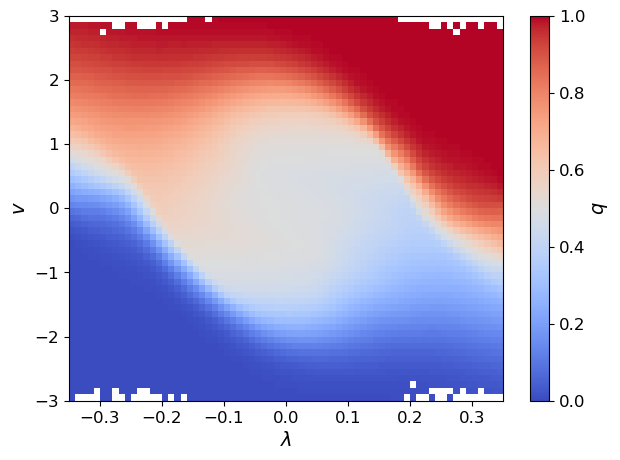

In [6]:
r = cp.asnumpy(q.r_traj)
edges_l = np.linspace(lambda_a, lambda_b, 71)
edges_v = np.linspace(-3, 3, 61)
n, _, _ = np.histogram2d(lam, v, [edges_l, edges_v])
s, _, _ = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)
q_lv = np.where(n > 20, s / np.maximum(n, 1), np.nan)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
im = ax.pcolormesh(edges_l, edges_v, q_lv.T, cmap='coolwarm', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='$q$')
ax.set(xlabel='$\\lambda$', ylabel='$v$')
plt.show()

## 7. Save Results

Uncomment to save the raw committor trajectory to disk.

In [7]:
np.save('q_traj_langevin_env0.001g0.2.npy', cp.asnumpy(q.r_traj))